In [1]:
!pip install pycocotools opencv-python matplotlib pandas seaborn -q

print("Libraries installed successfully!")

Libraries installed successfully!


In [2]:
import os
import json
import glob
import cv2
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from google.colab import files
from pycocotools.coco import COCO

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

extract_path = "/content/traffic_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset uploaded and extracted successfully!")

Saving indian_traffic_coco_sample.zip to indian_traffic_coco_sample.zip
Dataset uploaded and extracted successfully!


In [4]:
json_files = glob.glob(
    extract_path + "/**/*.json",
    recursive=True
)

if not json_files:
    raise FileNotFoundError("COCO JSON annotation file not found!")

annotation_file = json_files[0]

with open(annotation_file, "r") as f:
    coco_data = json.load(f)

print("COCO Dataset Information")
print("------------------------")

print("Images:", len(coco_data["images"]))
print("Annotations:", len(coco_data["annotations"]))
print("Categories:", len(coco_data["categories"]))

COCO Dataset Information
------------------------
Images: 6
Annotations: 20
Categories: 5


In [5]:
categories = coco_data["categories"]

category_names = {
    category["id"]: category["name"]
    for category in categories
}

print("TRAFFIC OBJECT CATEGORIES")
print("-------------------------")

for category in categories:
    print("ID:", category["id"],
          "| Name:", category["name"])

TRAFFIC OBJECT CATEGORIES
-------------------------
ID: 1 | Name: car
ID: 2 | Name: bus
ID: 3 | Name: motorcycle
ID: 4 | Name: person
ID: 5 | Name: auto_rickshaw


In [6]:
category_counts = Counter()

for annotation in coco_data["annotations"]:

    category_id = annotation["category_id"]

    category_counts[
        category_names[category_id]
    ] += 1

df = pd.DataFrame(
    category_counts.items(),
    columns=["Traffic Category", "Number of Objects"]
)

print(df)

  Traffic Category  Number of Objects
0              car                  6
1    auto_rickshaw                  5
2              bus                  5
3           person                  3
4       motorcycle                  1


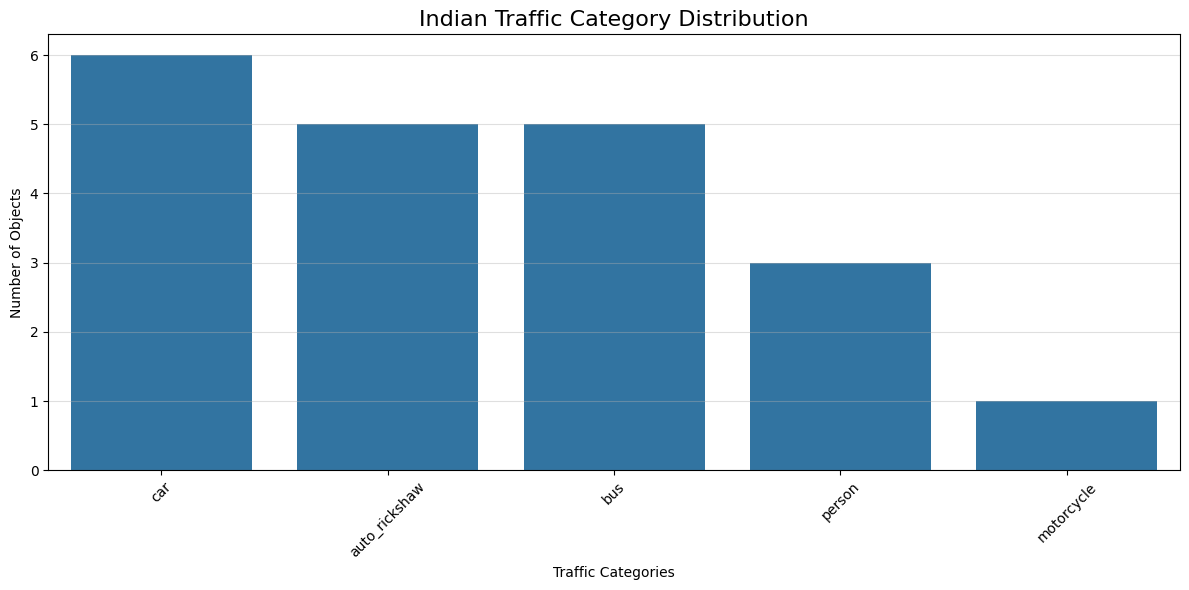

In [7]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Traffic Category",
    y="Number of Objects"
)

plt.title("Indian Traffic Category Distribution", fontsize=16)
plt.xlabel("Traffic Categories")
plt.ylabel("Number of Objects")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()

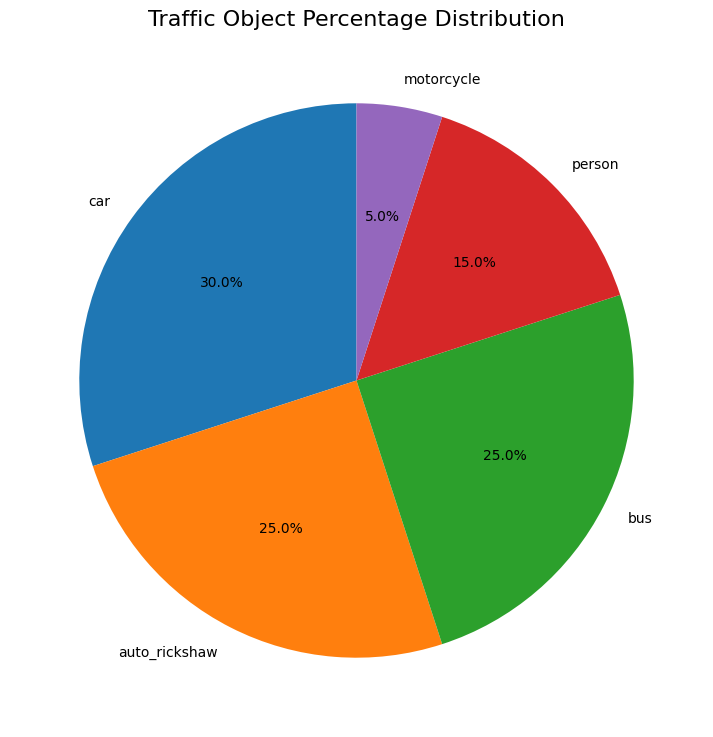

In [8]:
plt.figure(figsize=(9, 9))

plt.pie(
    df["Number of Objects"],
    labels=df["Traffic Category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Traffic Object Percentage Distribution", fontsize=16)

plt.show()

In [9]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_map = {}

for root, dirs, filenames in os.walk(extract_path):

    for filename in filenames:

        if filename.lower().endswith(image_extensions):

            image_map[filename] = os.path.join(
                root, filename
            )

print("Total images found:", len(image_map))

Total images found: 6


In [10]:
def visualize_image(image_id):

    image_info = next(
        img for img in coco_data["images"]
        if img["id"] == image_id
    )

    filename = os.path.basename(image_info["file_name"])

    image_path = image_map.get(filename)

    if image_path is None:
        print("Image not found:", filename)
        return

    image = cv2.imread(image_path)

    if image is None:
        print("Unable to read image!")
        return

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    annotations = [
        ann for ann in coco_data["annotations"]
        if ann["image_id"] == image_id
    ]

    for ann in annotations:

        x, y, w, h = map(int, ann["bbox"])

        label = category_names[ann["category_id"]]

        cv2.rectangle(
            image,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            image,
            label,
            (x, max(y - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.title("Traffic Image with Bounding Boxes")
    plt.axis("off")
    plt.show()

    print("Image:", filename)
    print("Total Objects:", len(annotations))

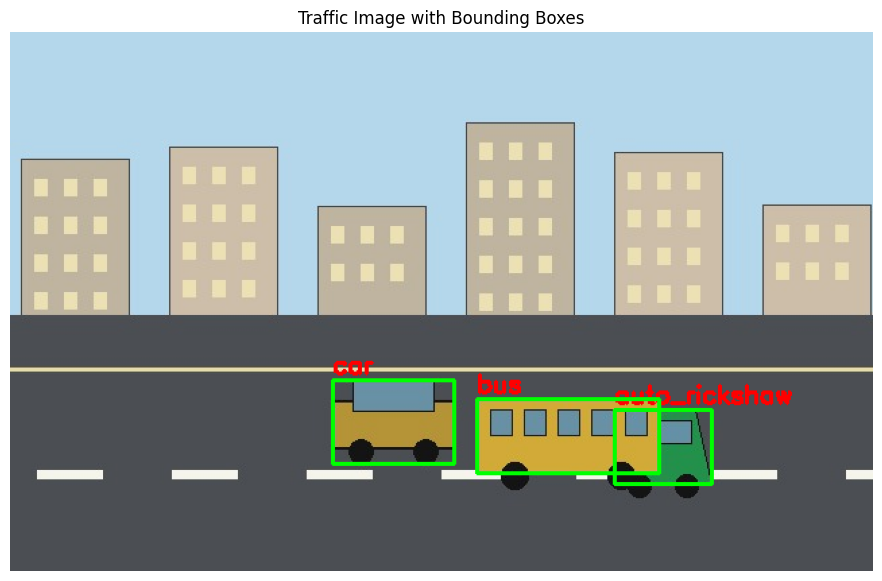

Image: traffic_01.jpg
Total Objects: 3


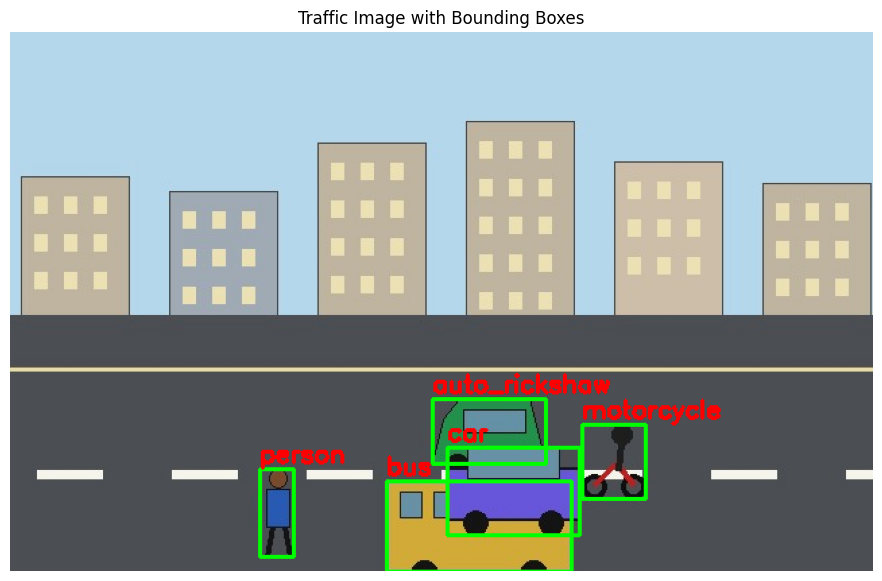

Image: traffic_02.jpg
Total Objects: 5


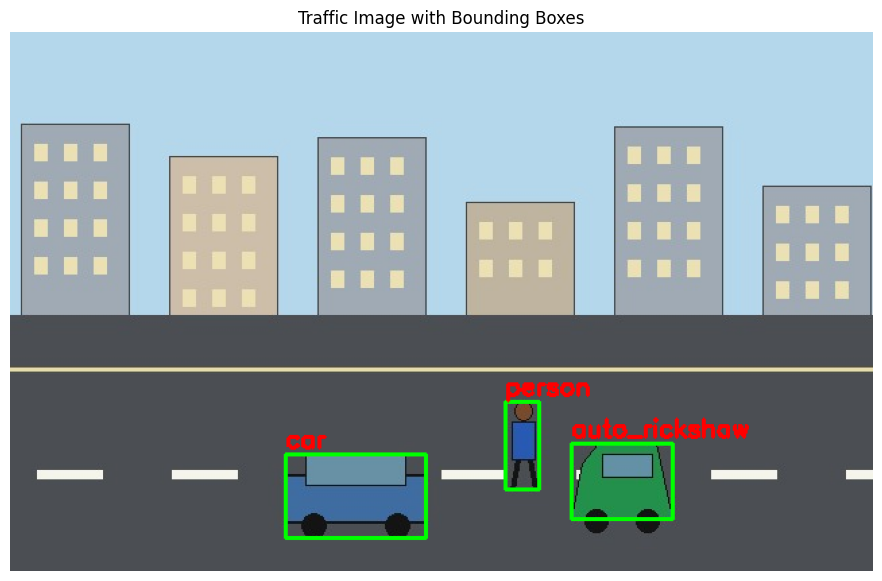

Image: traffic_03.jpg
Total Objects: 3


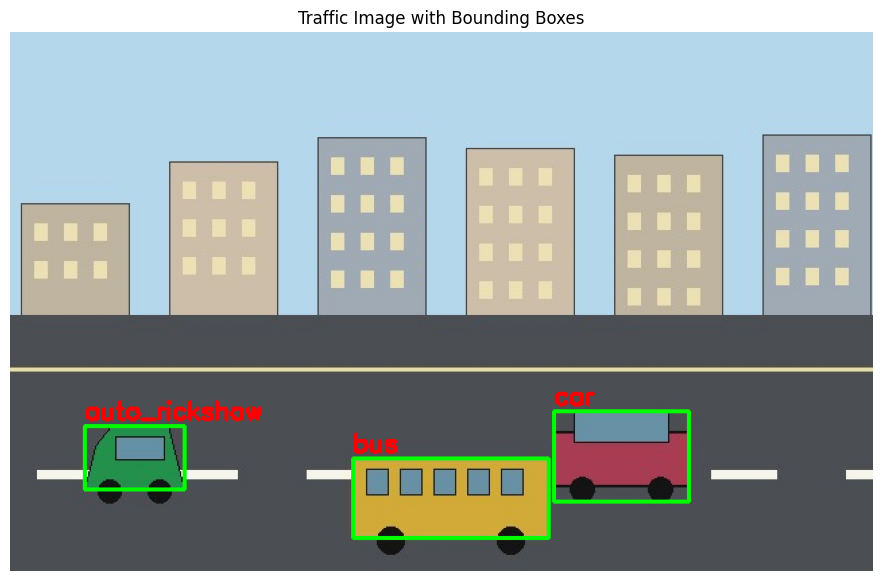

Image: traffic_04.jpg
Total Objects: 3


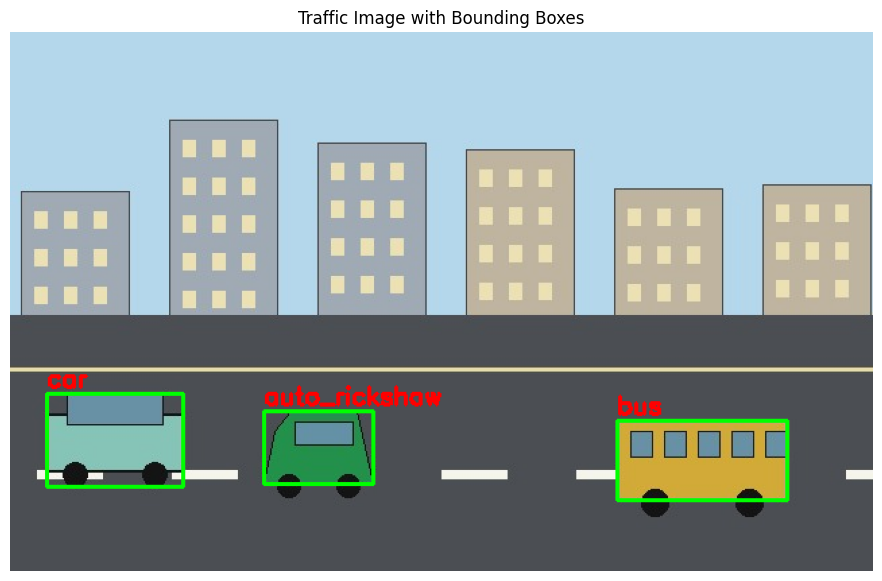

Image: traffic_05.jpg
Total Objects: 3


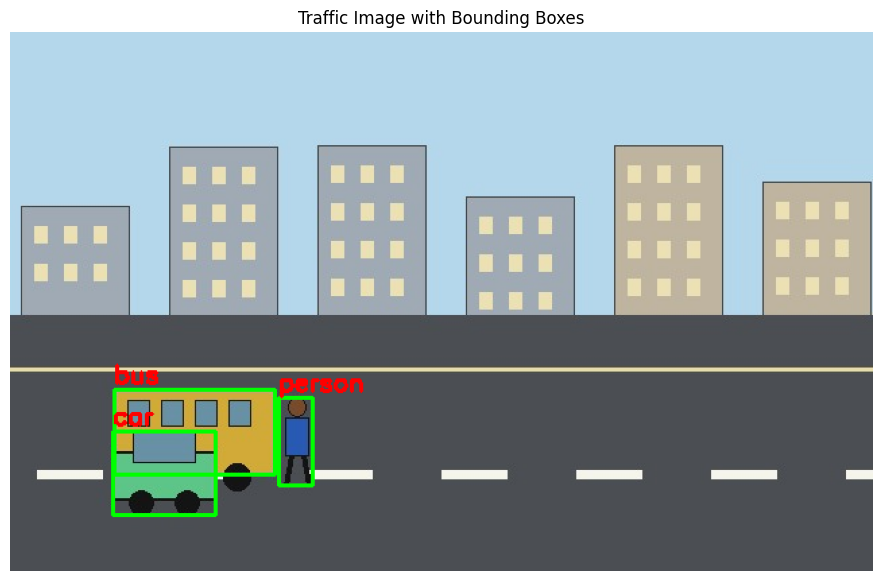

Image: traffic_06.jpg
Total Objects: 3


In [11]:
sample_images = coco_data["images"][:6]

for img in sample_images:

    visualize_image(img["id"])

In [12]:
annotation_details = []

for ann in coco_data["annotations"]:

    x, y, width, height = ann["bbox"]

    annotation_details.append({

        "Image ID": ann["image_id"],

        "Category": category_names[ann["category_id"]],

        "X Coordinate": x,

        "Y Coordinate": y,

        "Width": width,

        "Height": height

    })

annotation_df = pd.DataFrame(annotation_details)

annotation_df["Box Area"] = (
    annotation_df["Width"] *
    annotation_df["Height"]
)

print(annotation_df.head(10))

   Image ID       Category  X Coordinate  Y Coordinate  Width  Height  \
0         1            car           239           258     90      62   
1         1  auto_rickshaw           448           280     72      55   
2         1            bus           346           272    135      55   
3         2  auto_rickshaw           313           272     84      48   
4         2            bus           279           333    137      67   
5         2         person           185           324     25      65   
6         2            car           324           308     98      65   
7         2     motorcycle           424           291     47      55   
8         3         person           367           274     25      65   
9         3  auto_rickshaw           416           305     75      56   

   Box Area  
0      5580  
1      3960  
2      7425  
3      4032  
4      9179  
5      1625  
6      6370  
7      2585  
8      1625  
9      4200  


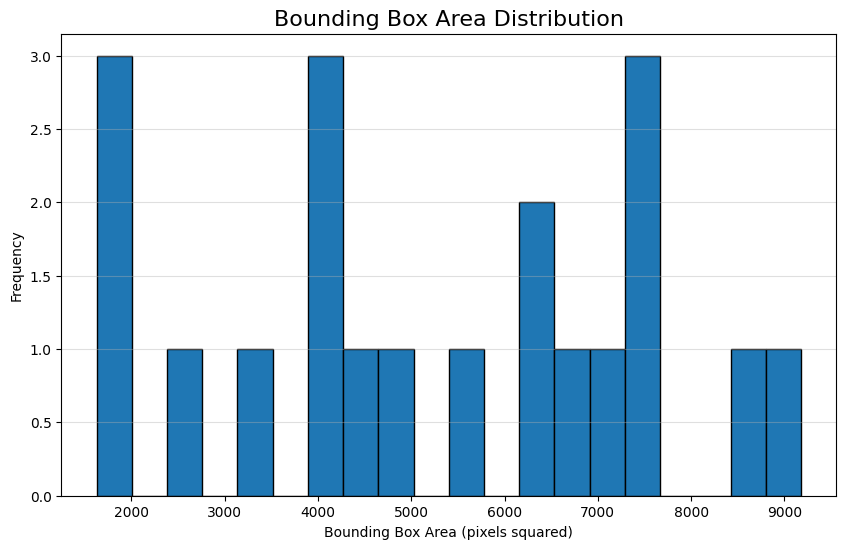

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(
    annotation_df["Box Area"],
    bins=20,
    edgecolor="black"
)

plt.title("Bounding Box Area Distribution", fontsize=16)
plt.xlabel("Bounding Box Area (pixels squared)")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.4)
plt.show()

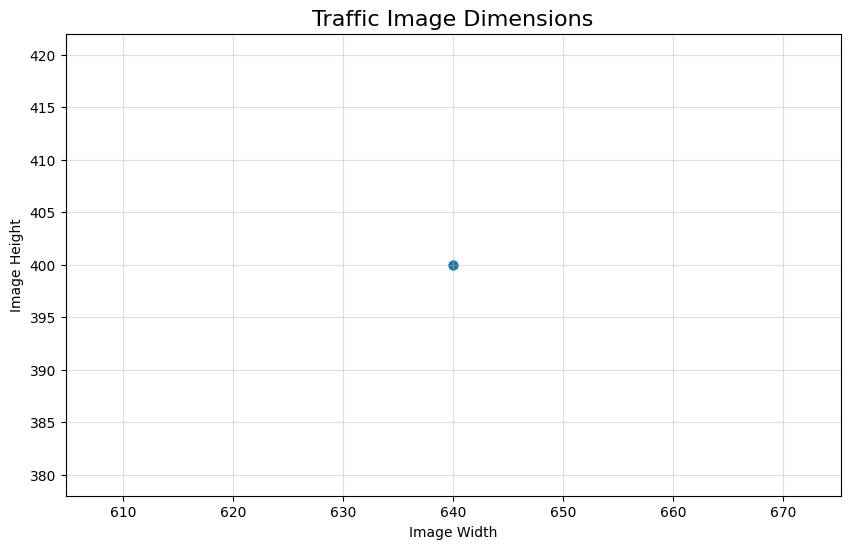

In [14]:
image_sizes = pd.DataFrame(coco_data["images"])

plt.figure(figsize=(10, 6))

plt.scatter(
    image_sizes["width"],
    image_sizes["height"],
    alpha=0.6
)

plt.title("Traffic Image Dimensions", fontsize=16)
plt.xlabel("Image Width")
plt.ylabel("Image Height")

plt.grid(alpha=0.4)
plt.show()

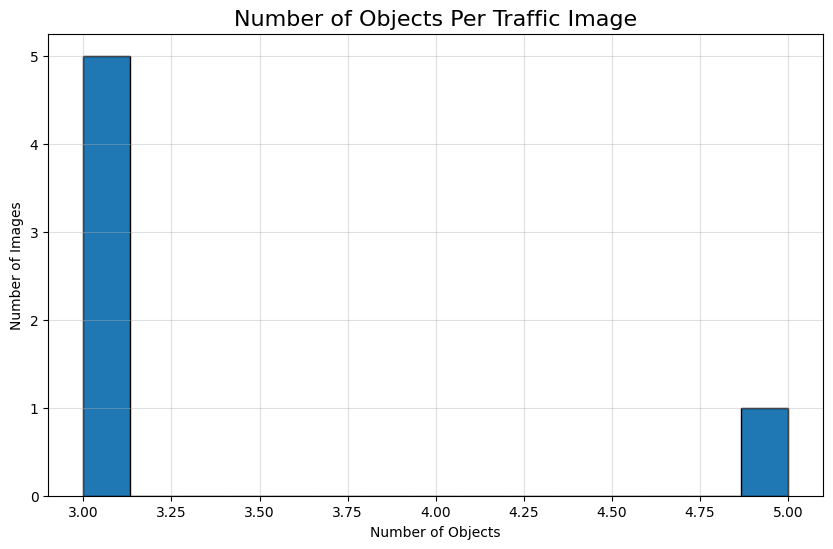

In [15]:
objects_per_image = annotation_df.groupby(
    "Image ID"
).size()

plt.figure(figsize=(10, 6))

plt.hist(
    objects_per_image,
    bins=15,
    edgecolor="black"
)

plt.title("Number of Objects Per Traffic Image", fontsize=16)
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

plt.grid(alpha=0.4)
plt.show()

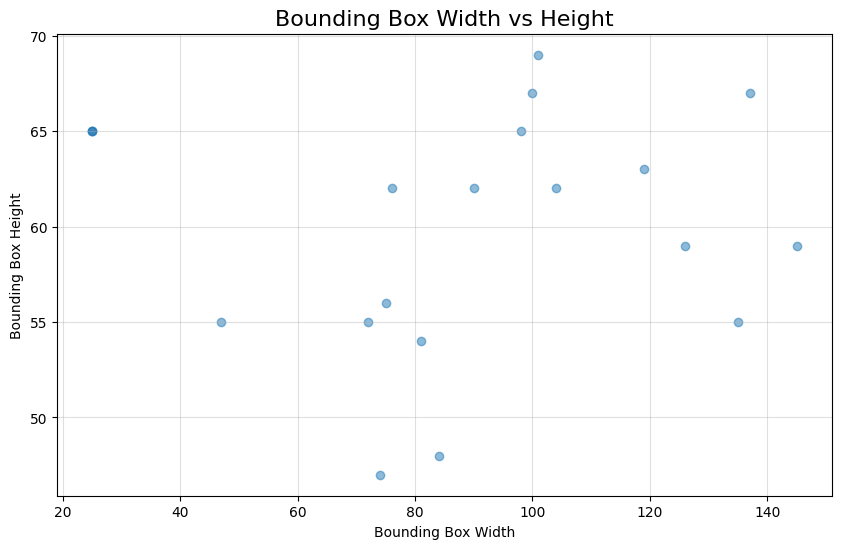

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(
    annotation_df["Width"],
    annotation_df["Height"],
    alpha=0.5
)

plt.title("Bounding Box Width vs Height", fontsize=16)
plt.xlabel("Bounding Box Width")
plt.ylabel("Bounding Box Height")

plt.grid(alpha=0.4)
plt.show()

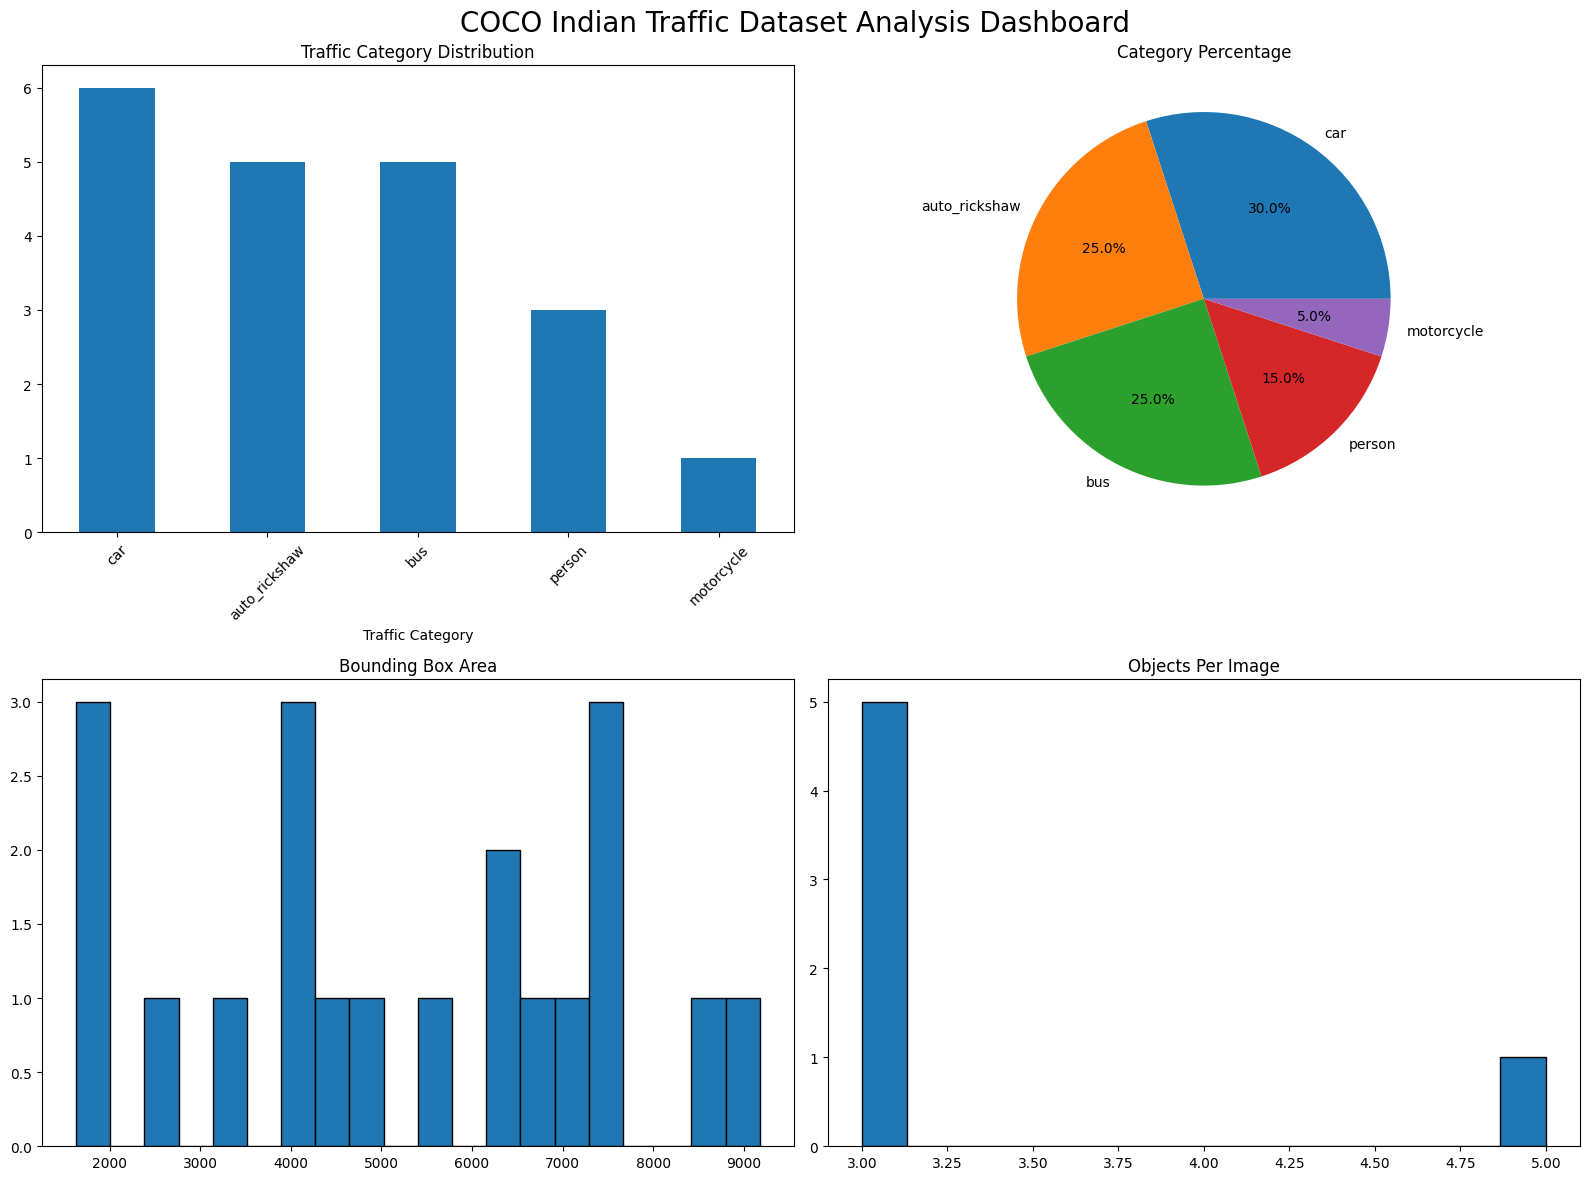

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Category distribution
df.plot(
    kind="bar",
    x="Traffic Category",
    y="Number of Objects",
    ax=axes[0, 0],
    legend=False
)

axes[0, 0].set_title("Traffic Category Distribution")
axes[0, 0].tick_params(axis="x", rotation=45)

# Category pie chart
axes[0, 1].pie(
    df["Number of Objects"],
    labels=df["Traffic Category"],
    autopct="%1.1f%%"
)

axes[0, 1].set_title("Category Percentage")

# Bounding box area
axes[1, 0].hist(
    annotation_df["Box Area"],
    bins=20,
    edgecolor="black"
)

axes[1, 0].set_title("Bounding Box Area")

# Objects per image
axes[1, 1].hist(
    objects_per_image,
    bins=15,
    edgecolor="black"
)

axes[1, 1].set_title("Objects Per Image")

plt.suptitle(
    "COCO Indian Traffic Dataset Analysis Dashboard",
    fontsize=20
)

plt.tight_layout()
plt.show()

In [21]:
output_file = "/content/traffic_annotation_results.csv"

annotation_df.to_csv(output_file, index=False)

print("CSV file saved successfully!")

files.download(output_file)

CSV file saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
dashboard_path = "/content/traffic_dashboard.png"

fig.savefig(
    dashboard_path,
    dpi=300,
    bbox_inches="tight"
)

print("Dashboard saved successfully!")

files.download(dashboard_path)

Dashboard saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
print("=" * 55)
print("COCO DATASET EXPLORATION - PROJECT REPORT")
print("=" * 55)

print("Total Images:", len(coco_data["images"]))

print("Total Annotations:", len(coco_data["annotations"]))

print("Total Categories:", len(coco_data["categories"]))

print("Total Image Files Found:", len(image_map))

print("\nCATEGORY DISTRIBUTION")

print(df.to_string(index=False))

print("\nTOTAL BOUNDING BOXES:", len(annotation_df))

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("=" * 55)

COCO DATASET EXPLORATION - PROJECT REPORT
Total Images: 6
Total Annotations: 20
Total Categories: 5
Total Image Files Found: 6

CATEGORY DISTRIBUTION
Traffic Category  Number of Objects
             car                  6
   auto_rickshaw                  5
             bus                  5
          person                  3
      motorcycle                  1

TOTAL BOUNDING BOXES: 20

PROJECT COMPLETED SUCCESSFULLY!
